# Customer Segmentation Using Unsupervised Machine Learning

**IBM Unsupervised Machine Learning — Final Project**

## Project Overview

This notebook segments **440 clients of a wholesale distributor** based on their annual spending across six product categories. The dataset has no target label, so the task is approached with **unsupervised clustering**.

**Objective:** discover meaningful customer segments and translate them into practical recommendations for marketing, customer relationship management, and inventory planning.

**Workflow**
1. Dataset loading and exploration
2. Exploratory data analysis (EDA)
3. Data preprocessing (cleaning, log transformation, standard scaling)
4. K-Means clustering
5. PCA visualization
6. Agglomerative (hierarchical) clustering
7. DBSCAN
8. Model comparison and final model selection
9. Customer segmentation and profiling
10. Business insights and conclusion

**Dataset:** Cardoso, M. (2013). *Wholesale customers* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5030X — licensed under CC BY 4.0.

### Setup: import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Dataset Loading and Exploration

Load the dataset and inspect its structure, data types, summary statistics, missing values, and duplicates.

`Channel` (1 = Horeca, 2 = Retail) and `Region` (1 = Lisbon, 2 = Oporto, 3 = Other) are categorical. The remaining six columns are annual spending in monetary units.

In [2]:
data = pd.read_csv("wholesale_customers.csv")
data.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
data.shape

(440, 8)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [5]:
data.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [6]:
data.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [7]:
data.duplicated().sum()

np.int64(0)

In [8]:
data.dtypes

,0
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


In [9]:
data["Region"].value_counts()

,count
Region,
3,316
1,77
2,47


## 2. Exploratory Data Analysis (EDA)

Clustering is based on the six annual spending features. The charts below show their distributions, how they correlate, and where the outliers are.

In [10]:
spending_columns = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

data[spending_columns].head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


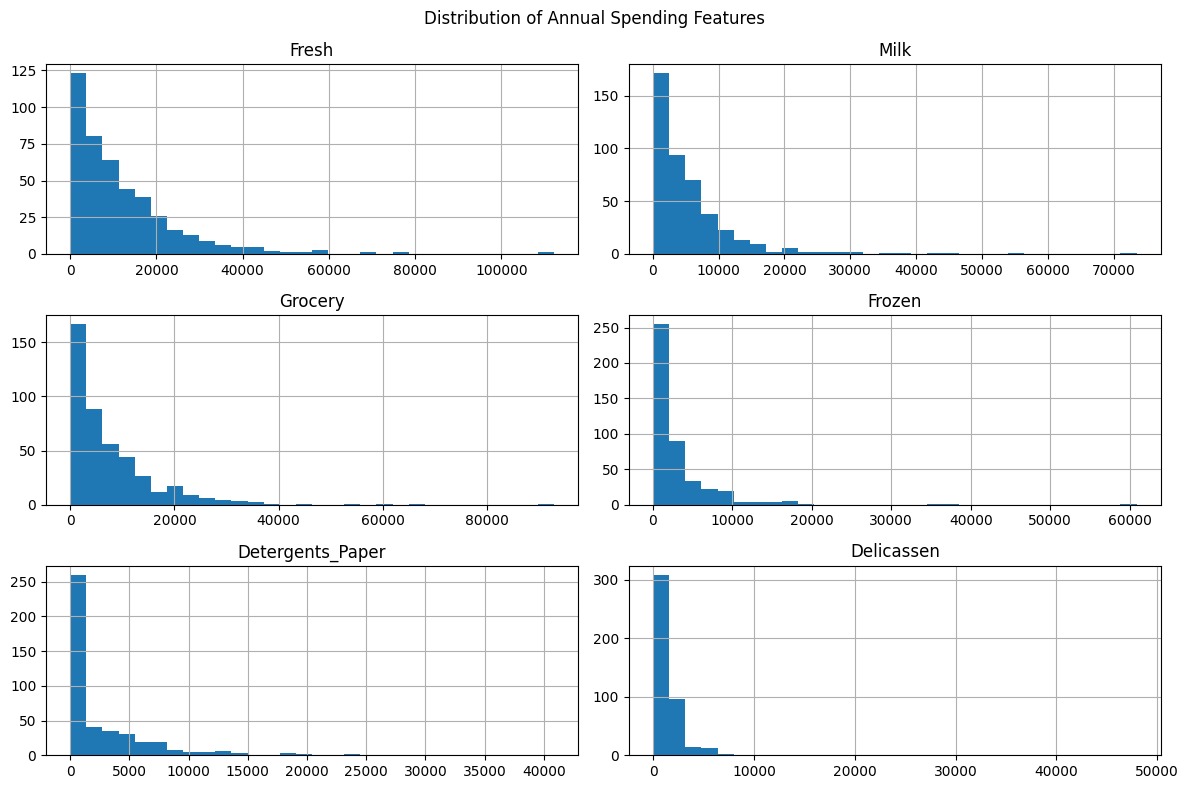

In [11]:
data[spending_columns].hist(figsize=(12, 8), bins=30)

plt.suptitle("Distribution of Annual Spending Features")
plt.tight_layout()
plt.show()

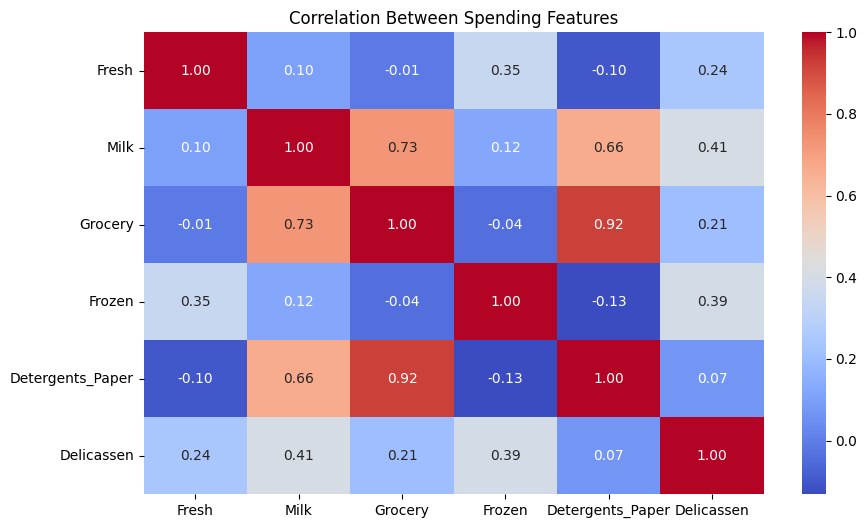

In [12]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    data[spending_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Spending Features")
plt.show()

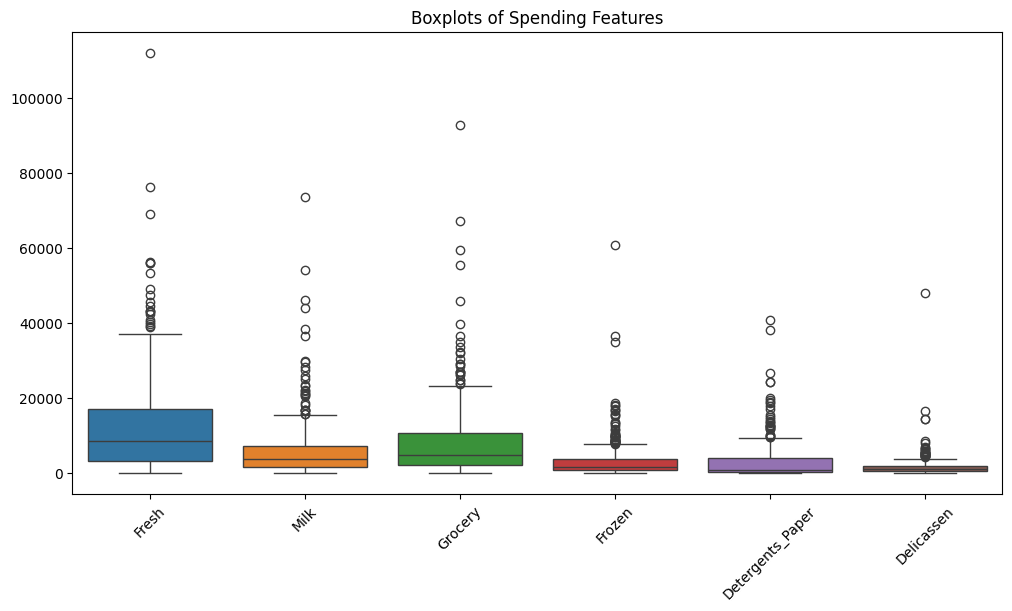

In [13]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=data[spending_columns])

plt.title("Boxplots of Spending Features")
plt.xticks(rotation=45)
plt.show()

## 3. Data Preprocessing

### 3.1 Data cleaning

Work on a copy of the raw data, then confirm there are no missing values or duplicate rows.

In [14]:
data_clean = data.copy()

print("Original data shape:", data_clean.shape)

Original data shape: (440, 8)


In [15]:
missing_values = data_clean.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


In [16]:
duplicates_count = data_clean.duplicated().sum()

print("Number of duplicated rows:", duplicates_count)

data_clean = data_clean.drop_duplicates()

print("Data shape after removing duplicates:", data_clean.shape)

Number of duplicated rows: 0
Data shape after removing duplicates: (440, 8)


### 3.2 Feature selection

Only the six spending features are used for clustering. `Channel` and `Region` are kept aside and used later to profile the segments.

In [17]:
spending_columns = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

X = data_clean[spending_columns]

In [18]:
X.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


### 3.3 Skewness and log transformation

The spending features are strongly right-skewed: a few customers spend far more than the rest. Distance-based clustering is sensitive to extreme values, so a `log(1 + x)` transformation is applied to reduce skewness.

In [19]:
skewness_before = X.skew()

print("Skewness before transformation:")
print(skewness_before)

Skewness before transformation:
Fresh                2.561323
Milk                 4.053755
Grocery              3.587429
Frozen               5.907986
Detergents_Paper     3.631851
Delicassen          11.151586
dtype: float64


In [20]:
X_log = np.log1p(X)

In [21]:
X_log.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,9.446992,9.175438,8.930891,5.370638,7.891705,7.199678
1,8.861917,9.191259,9.166284,7.474772,8.099858,7.482682
2,8.756840,9.083529,8.947026,7.785721,8.165364,8.967632
3,9.492960,7.087574,8.348064,8.764834,6.230481,7.489412
4,10.026413,8.596189,8.881697,8.272826,7.483244,8.553718


In [22]:
skewness_after = X_log.skew()

print("Skewness after log transformation:")
print(skewness_after)

Skewness after log transformation:
Fresh              -1.575326
Milk               -0.224063
Grocery            -0.674938
Frozen             -0.352655
Detergents_Paper   -0.235961
Delicassen         -1.091827
dtype: float64


In [23]:
skewness_comparison = pd.DataFrame({
    "Before Log Transformation": skewness_before,
    "After Log Transformation": skewness_after
})

skewness_comparison

,Before Log Transformation,After Log Transformation
Fresh,2.561323,-1.575326
Milk,4.053755,-0.224063
Grocery,3.587429,-0.674938
Frozen,5.907986,-0.352655
Detergents_Paper,3.631851,-0.235961
Delicassen,11.151586,-1.091827


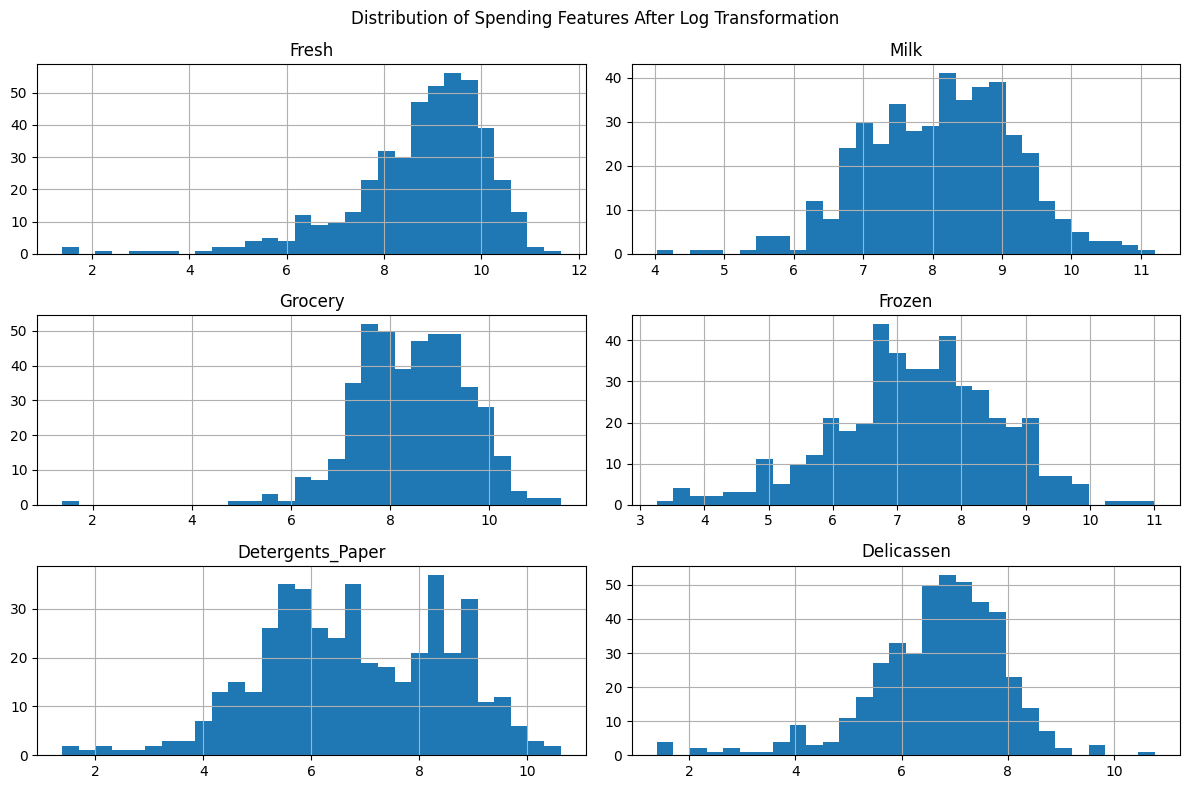

In [24]:
X_log.hist(figsize=(12, 8), bins=30)

plt.suptitle("Distribution of Spending Features After Log Transformation")
plt.tight_layout()
plt.show()

### 3.4 Standard scaling

After the log transformation, `StandardScaler` puts every feature on a comparable scale (mean 0, standard deviation 1). Without this, features with larger values would dominate the distance calculations.

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=spending_columns
)

X_scaled_df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.486184,0.976299,0.440155,-1.509250,0.644143,0.408966
1,0.087889,0.990956,0.652171,0.134052,0.766043,0.627926
2,0.016356,0.891151,0.454687,0.376899,0.804405,1.776833
3,0.517477,-0.957973,-0.084792,1.141574,-0.328712,0.633133
4,0.880631,0.439662,0.395847,0.757322,0.404939,1.456588


In [26]:

X_scaled_df.describe()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,4.400000e+02,4.400000e+02,4.400000e+02,4.400000e+02,4.400000e+02,4.400000e+02
mean,2.826022e-17,-7.105427e-16,-1.073888e-15,2.826022e-16,-6.378736e-16,-1.614870e-17
std,1.001138e+00,1.001138e+00,1.001138e+00,1.001138e+00,1.001138e+00,1.001138e+00
min,-5.001217e+00,-3.794924e+00,-6.355190e+00,-3.159118e+00,-3.165591e+00,-4.088856e+00
25%,-4.659360e-01,-7.281616e-01,-6.909415e-01,-5.405240e-01,-7.260542e-01,-5.081462e-01
50%,2.148413e-01,6.931547e-02,2.257341e-02,2.180154e-02,-5.009412e-02,1.567407e-01
75%,6.836939e-01,7.031679e-01,7.491423e-01,6.818408e-01,8.683740e-01,6.469559e-01
max,1.970662e+00,2.856582e+00,2.698281e+00,2.900093e+00,2.240218e+00,3.177354e+00


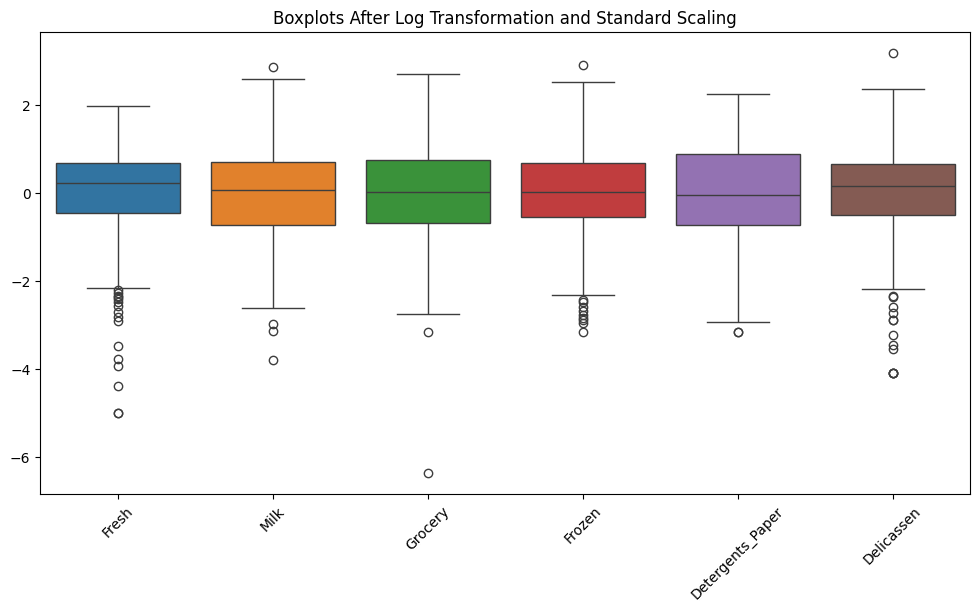

In [27]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=X_scaled_df)

plt.title("Boxplots After Log Transformation and Standard Scaling")
plt.xticks(rotation=45)
plt.show()

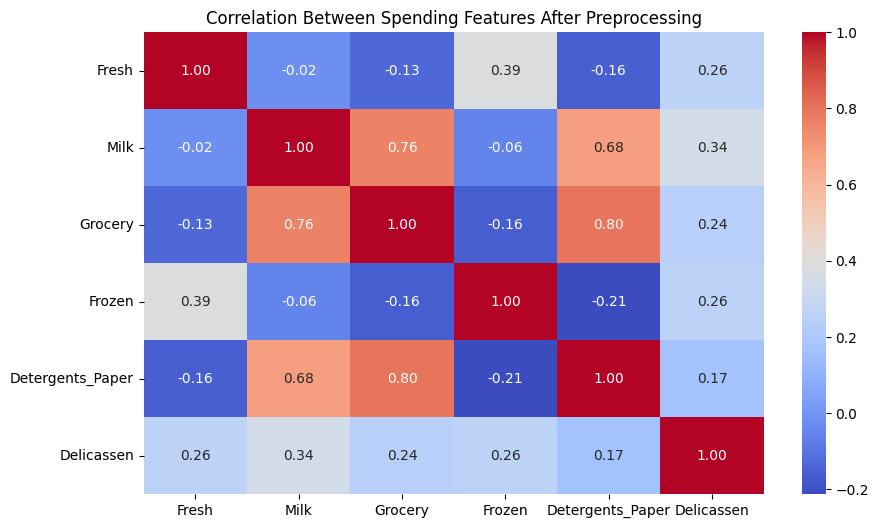

In [28]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    X_scaled_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Spending Features After Preprocessing")
plt.show()

## 4. K-Means Clustering

K-Means is fitted for K = 2 to 10 (`random_state=42`, `n_init=10`). Each K is evaluated with:
- **Inertia** (elbow method): within-cluster sum of squares
- **Silhouette score**: how well separated the clusters are (higher is better)

In [29]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []

k_values = range(2, 11)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled_df)

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(X_scaled_df, cluster_labels)
    )

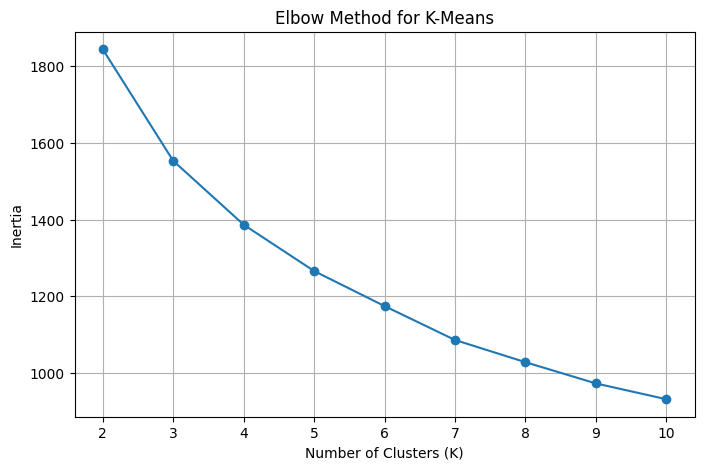

In [30]:


plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia_values, marker="o")

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

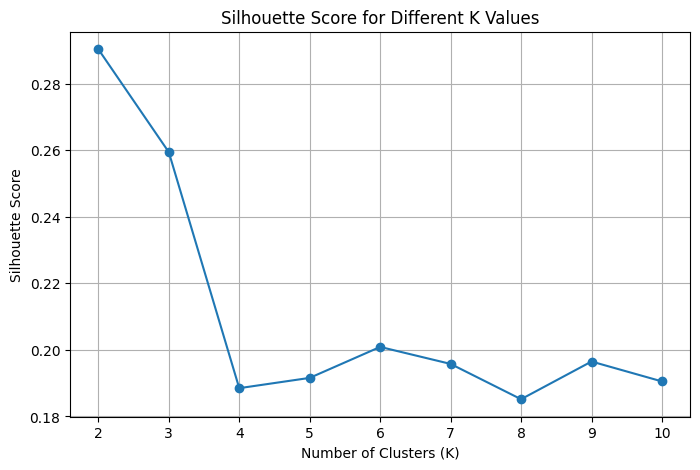

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, silhouette_values, marker="o")

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

### 4.1 K-Means results by K

**Note on choosing K:** K = 2 has the highest silhouette score (≈ 0.290). K = 3 has the second highest (≈ 0.259) and is clearly better than K ≥ 4. **K = 3 was selected for business interpretability**: it separates a high-value broad-spending group from two groups with distinct product preferences, which gives more actionable segments than a two-way split. It was not chosen to maximize the silhouette score.

In [32]:
kmeans_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

kmeans_results

,K,Inertia,Silhouette Score
0,2,1844.064069,0.290328
1,3,1553.421327,0.259416
2,4,1386.862741,0.188495
3,5,1266.149362,0.191585
4,6,1174.758633,0.200887
5,7,1086.358700,0.195780
6,8,1028.486217,0.185175
7,9,973.141483,0.196501
8,10,931.998464,0.190523


### 4.2 Final K-Means model (K = 3)

Fit the final model and assign each customer a cluster label, then look at cluster sizes and average spending per cluster.

In [33]:
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

data_clean["KMeans_Cluster"] = final_kmeans.fit_predict(X_scaled_df)

data_clean.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,2
4,2,3,22615,5410,7198,3915,1777,5185,1


In [34]:


data_clean["KMeans_Cluster"].value_counts().sort_index()

,count
KMeans_Cluster,
0,80
1,147
2,213


In [35]:
kmeans_cluster_profile = data_clean.groupby("KMeans_Cluster")[spending_columns].mean()

kmeans_cluster_profile

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Cluster,,,,,,
0,2898.575000,7135.937500,12569.712500,606.550000,5554.387500,782.862500
1,17042.836735,10559.666667,13333.598639,4133.095238,4987.020408,2846.591837
2,11938.723005,2005.685446,2502.093897,3265.544601,424.478873,891.384977


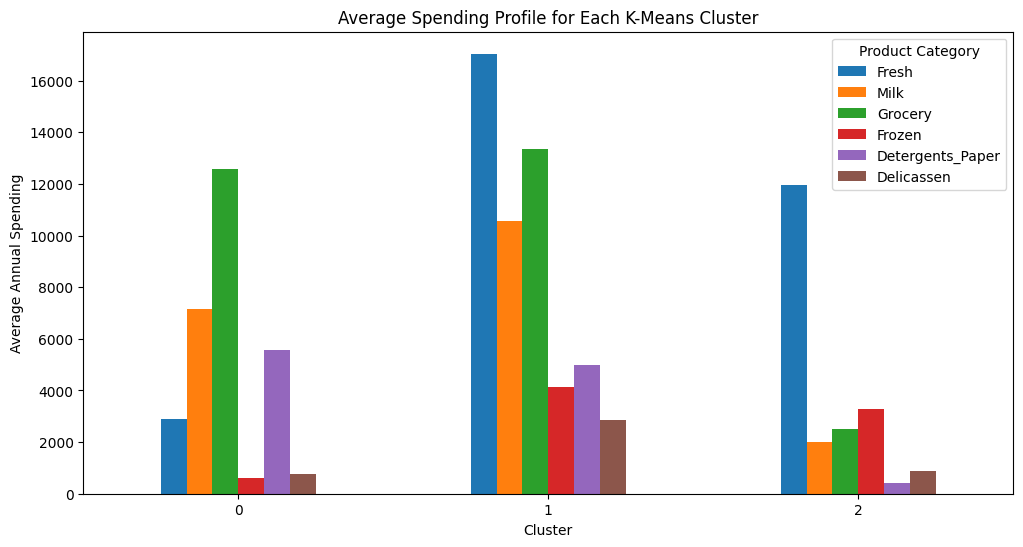

In [36]:
kmeans_cluster_profile.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Spending Profile for Each K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Annual Spending")
plt.xticks(rotation=0)
plt.legend(title="Product Category")
plt.show()

## 5. PCA Visualization

PCA projects the six scaled features onto two principal components **for visualization only**. The clustering itself uses all six features.

In [37]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled_df)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["KMeans_Cluster"] = data_clean["KMeans_Cluster"]

pca_df.head()

,PC1,PC2,KMeans_Cluster
0,1.380383,-0.304727,1
1,1.438870,0.537468,1
2,1.513453,1.232565,1
3,-0.825105,1.210790,2
4,0.802897,1.766046,1


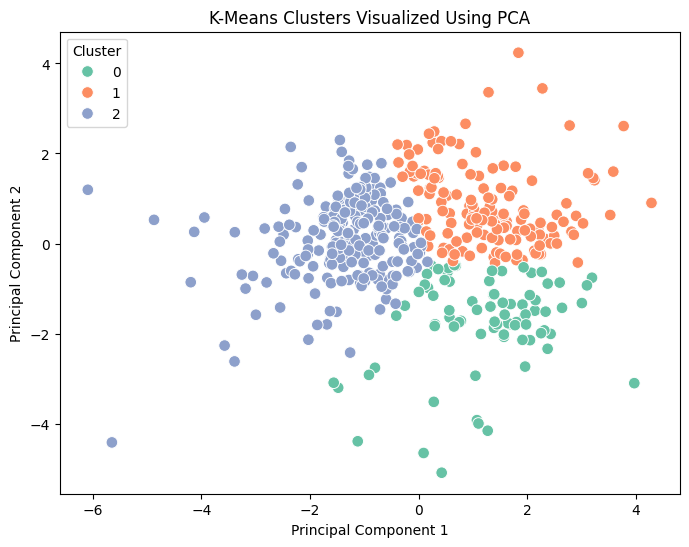

In [38]:


plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="KMeans_Cluster",
    palette="Set2",
    s=70
)

plt.title("K-Means Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

In [39]:


explained_variance = pca.explained_variance_ratio_

print("Explained variance by PC1:", explained_variance[0])
print("Explained variance by PC2:", explained_variance[1])
print("Total explained variance:", explained_variance.sum())

Explained variance by PC1: 0.44077751785700686
Explained variance by PC2: 0.27194917148586895
Total explained variance: 0.7127266893428759


## 6. Agglomerative (Hierarchical) Clustering

Agglomerative clustering with **Ward linkage** merges clusters in a way that minimizes the increase in within-cluster variance. The number of clusters is tested from 2 to 10 and evaluated with the silhouette score.

In [40]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [41]:
agg_silhouette_scores = []

k_values = range(2, 11)

for k in k_values:

    agg_model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )


    agg_labels = agg_model.fit_predict(X_scaled_df)


    score = silhouette_score(X_scaled_df, agg_labels)

    agg_silhouette_scores.append(score)

In [42]:
agg_results = pd.DataFrame({
    "Number of Clusters": list(k_values),
    "Silhouette Score": agg_silhouette_scores
})

agg_results

,Number of Clusters,Silhouette Score
0,2,0.258495
1,3,0.254657
2,4,0.202080
3,5,0.202547
4,6,0.170707
5,7,0.163338
6,8,0.148217
7,9,0.155490
8,10,0.121827


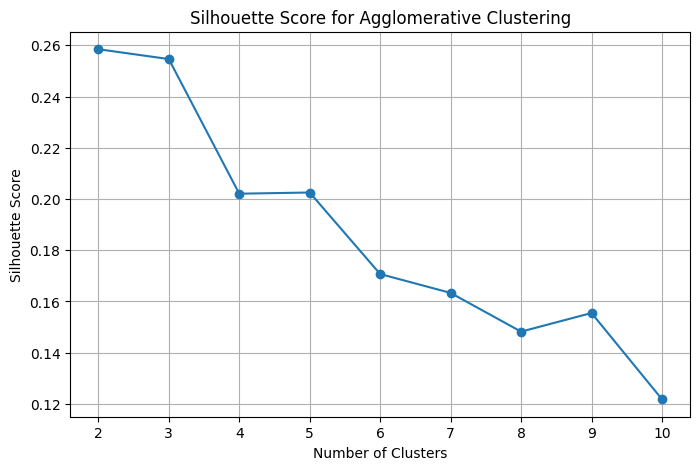

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, agg_silhouette_scores, marker="o")

plt.title("Silhouette Score for Agglomerative Clustering")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

### 6.1 Dendrogram

The dendrogram (truncated to the last 20 merges) shows the hierarchical structure of the data.

In [44]:
from scipy.cluster.hierarchy import linkage, dendrogram

In [45]:
linked = linkage(X_scaled_df, method="ward")

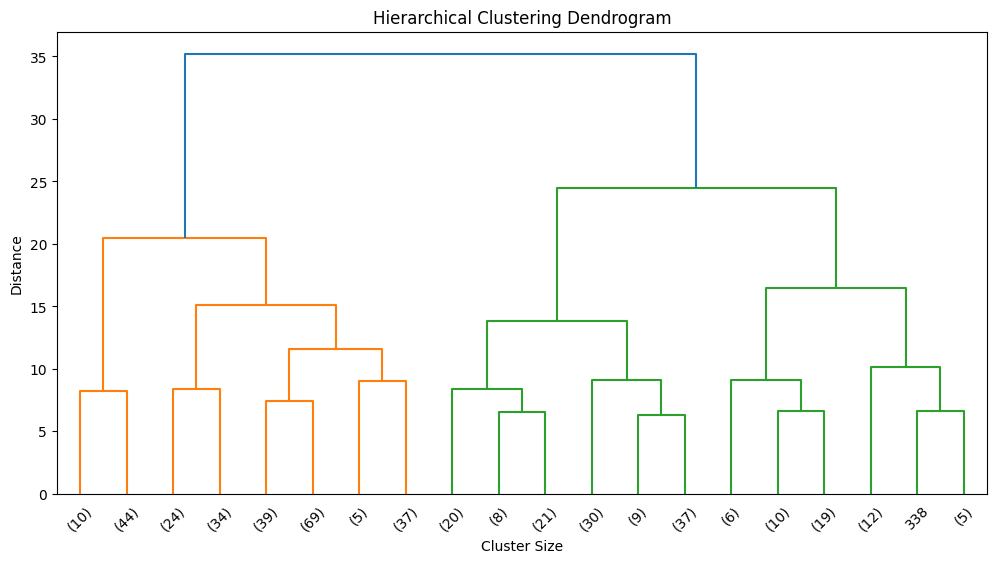

In [46]:
plt.figure(figsize=(12, 6))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=20,
    leaf_rotation=45,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster Size")
plt.ylabel("Distance")
plt.show()

### 6.2 Final agglomerative model (K = 3)

K = 3 is used so the result can be compared directly with K-Means.

In [47]:
final_agg = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)


data_clean["Agglomerative_Cluster"] = final_agg.fit_predict(X_scaled_df)

data_clean.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster,Agglomerative_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1,2
1,2,3,7057,9810,9568,1762,3293,1776,1,2
2,2,3,6353,8808,7684,2405,3516,7844,1,2
3,1,3,13265,1196,4221,6404,507,1788,2,0
4,2,3,22615,5410,7198,3915,1777,5185,1,0


In [48]:
data_clean["Agglomerative_Cluster"].value_counts().sort_index()

,count
Agglomerative_Cluster,
0,262
1,53
2,125


In [49]:
agg_cluster_profile = data_clean.groupby("Agglomerative_Cluster")[spending_columns].mean()

agg_cluster_profile

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Agglomerative_Cluster,,,,,,
0,15016.099237,3389.935115,3673.954198,4187.851145,616.805344,1552.751908
1,3913.962264,5222.981132,8657.924528,1198.415094,3474.113208,190.490566
2,9107.784000,11083.008000,16616.928000,1527.336000,7377.008000,2032.208000


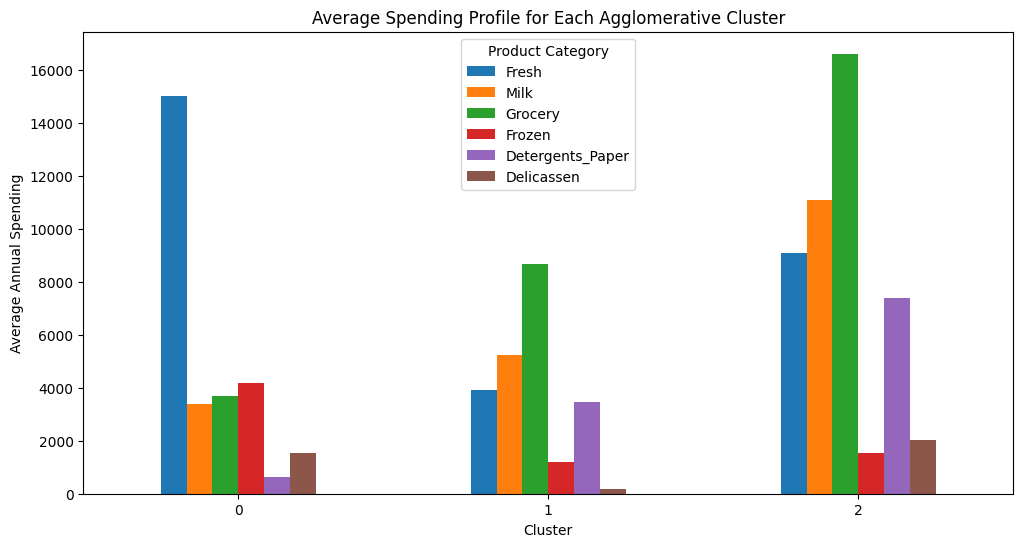

In [50]:
agg_cluster_profile.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Spending Profile for Each Agglomerative Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Annual Spending")
plt.xticks(rotation=0)
plt.legend(title="Product Category")
plt.show()

In [51]:
pca_df["Agglomerative_Cluster"] = data_clean["Agglomerative_Cluster"]

pca_df.head()

,PC1,PC2,KMeans_Cluster,Agglomerative_Cluster
0,1.380383,-0.304727,1,2
1,1.438870,0.537468,1,2
2,1.513453,1.232565,1,2
3,-0.825105,1.210790,2,0
4,0.802897,1.766046,1,0


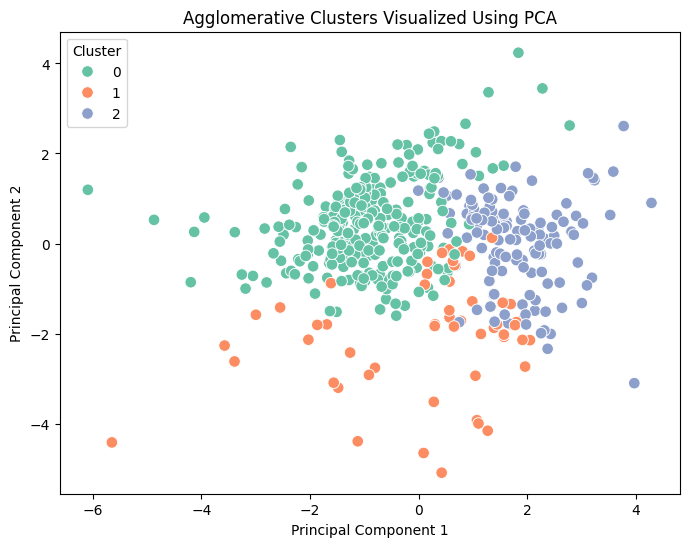

In [52]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Agglomerative_Cluster",
    palette="Set2",
    s=70
)

plt.title("Agglomerative Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

## 7. DBSCAN

DBSCAN is a density-based method. It does not need the number of clusters in advance and labels low-density points as **noise** (`-1`). A grid of `eps` and `min_samples` values is tested.

*Note:* in this grid search, `silhouette_score` is computed with noise points included as their own group, so these scores are not directly comparable with the K-Means and Agglomerative scores.

In [53]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

In [54]:

eps_values = [0.5, 0.7, 0.9, 1.1, 1.3, 1.5]
min_samples_values = [3, 5, 7]

dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan.fit_predict(X_scaled_df)


        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)


        n_noise = list(labels).count(-1)


        if n_clusters > 1:
            score = silhouette_score(X_scaled_df, labels)
        else:
            score = None

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "Number of Clusters": n_clusters,
            "Noise Points": n_noise,
            "Silhouette Score": score
        })

In [55]:


dbscan_results_df = pd.DataFrame(dbscan_results)

dbscan_results_df

,eps,min_samples,Number of Clusters,Noise Points,Silhouette Score
0,0.5,3,8,396,-0.399280
1,0.5,5,1,435,NaN
2,0.5,7,0,440,NaN
3,0.7,3,15,255,-0.303075
4,0.7,5,4,343,-0.224746
5,0.7,7,3,393,-0.287416
6,0.9,3,6,133,-0.226515
7,0.9,5,3,160,0.038999
8,0.9,7,2,191,-0.062001
9,1.1,3,3,72,0.046928


In [56]:
dbscan_results_df.sort_values(
    by="Silhouette Score",
    ascending=False
)

,eps,min_samples,Number of Clusters,Noise Points,Silhouette Score
15,1.5,3,2,35,0.298945
9,1.1,3,3,72,0.046928
7,0.9,5,3,160,0.038999
8,0.9,7,2,191,-0.062001
4,0.7,5,4,343,-0.224746
6,0.9,3,6,133,-0.226515
5,0.7,7,3,393,-0.287416
3,0.7,3,15,255,-0.303075
0,0.5,3,8,396,-0.399280
1,0.5,5,1,435,NaN


### 7.1 Final DBSCAN configuration

The configuration `eps=1.1`, `min_samples=5` gives one dense cluster plus noise points. DBSCAN is useful here for spotting unusual customers, but not for segmenting the whole customer base.

In [57]:
final_dbscan = DBSCAN(
    eps=1.1,
    min_samples=5
)

data_clean["DBSCAN_Cluster"] = final_dbscan.fit_predict(X_scaled_df)


data_clean.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster,Agglomerative_Cluster,DBSCAN_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1,2,0
1,2,3,7057,9810,9568,1762,3293,1776,1,2,0
2,2,3,6353,8808,7684,2405,3516,7844,1,2,0
3,1,3,13265,1196,4221,6404,507,1788,2,0,0
4,2,3,22615,5410,7198,3915,1777,5185,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...
95,1,3,3,2920,6252,440,223,709,0,1,-1
96,2,3,23,2616,8118,145,3874,217,0,1,-1
97,1,3,403,254,610,774,54,63,2,1,-1
98,1,3,503,112,778,895,56,132,2,1,-1


In [58]:
data_clean["DBSCAN_Cluster"].value_counts().sort_index()

,count
DBSCAN_Cluster,
-1,96
0,344


In [59]:

dbscan_labels = data_clean["DBSCAN_Cluster"]

n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in set(dbscan_labels) else 0)
n_noise_dbscan = list(dbscan_labels).count(-1)

print("Number of DBSCAN clusters:", n_clusters_dbscan)
print("Number of noise points:", n_noise_dbscan)

Number of DBSCAN clusters: 1
Number of noise points: 96


In [60]:
dbscan_cluster_profile = data_clean.groupby("DBSCAN_Cluster")[spending_columns].mean()

dbscan_cluster_profile

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
DBSCAN_Cluster,,,,,,
-1,12315.822917,9030.322917,12007.479167,3628.468750,4301.083333,2184.770833
0,11912.244186,4893.738372,6819.313953,2916.619186,2485.328488,1340.712209


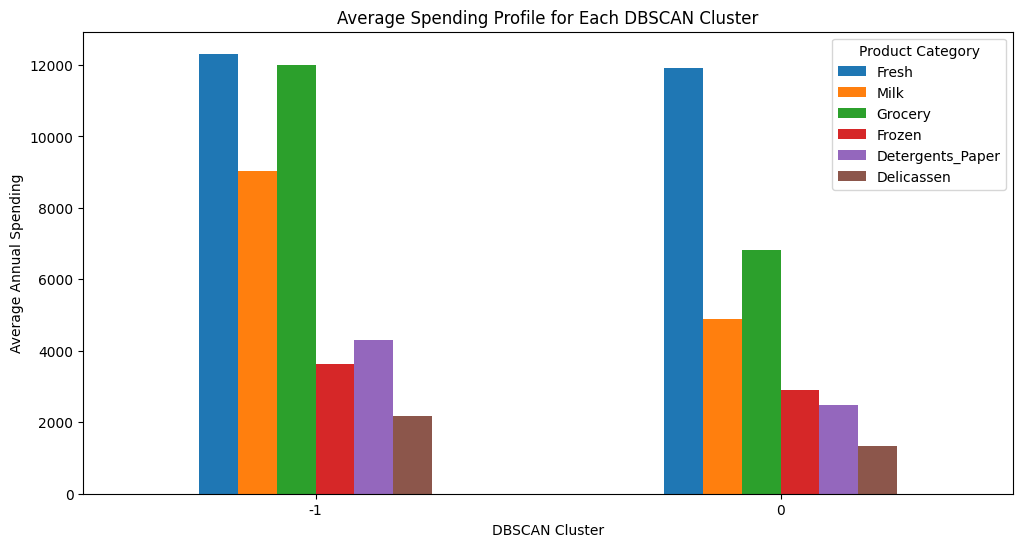

In [61]:
dbscan_cluster_profile.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Spending Profile for Each DBSCAN Cluster")
plt.xlabel("DBSCAN Cluster")
plt.ylabel("Average Annual Spending")
plt.xticks(rotation=0)
plt.legend(title="Product Category")
plt.show()

In [62]:
pca_df["DBSCAN_Cluster"] = data_clean["DBSCAN_Cluster"]

pca_df.head()

,PC1,PC2,KMeans_Cluster,Agglomerative_Cluster,DBSCAN_Cluster
0,1.380383,-0.304727,1,2,0
1,1.438870,0.537468,1,2,0
2,1.513453,1.232565,1,2,0
3,-0.825105,1.210790,2,0,0
4,0.802897,1.766046,1,0,0


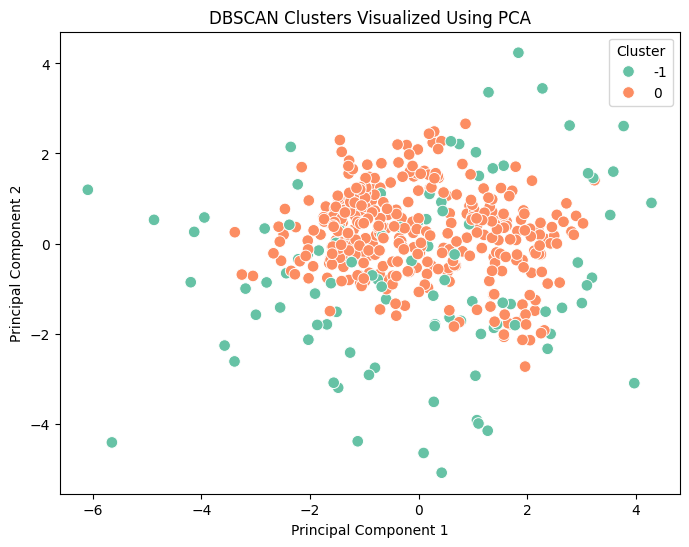

In [63]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="DBSCAN_Cluster",
    palette="Set2",
    s=70
)

plt.title("DBSCAN Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

### 7.2 K-distance plot

The sorted distance to each point's 5th nearest neighbor is a common heuristic for choosing `eps`.

In [64]:
from sklearn.neighbors import NearestNeighbors

In [65]:


neighbors = NearestNeighbors(n_neighbors=5)

neighbors_fit = neighbors.fit(X_scaled_df)

distances, indices = neighbors_fit.kneighbors(X_scaled_df)

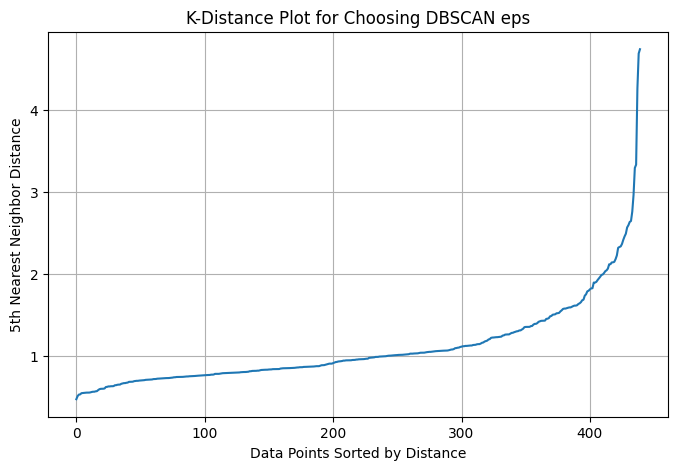

In [66]:
distances = np.sort(distances[:, 4])

plt.figure(figsize=(8, 5))

plt.plot(distances)

plt.title("K-Distance Plot for Choosing DBSCAN eps")
plt.xlabel("Data Points Sorted by Distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.grid(True)
plt.show()

## 8. Model Comparison

The three models are compared on number of clusters, noise points, and silhouette score. DBSCAN's silhouette score is undefined because it produced only one non-noise cluster, so it has no bar in the chart.

In [67]:
kmeans_labels = data_clean["KMeans_Cluster"]
agg_labels = data_clean["Agglomerative_Cluster"]
dbscan_labels = data_clean["DBSCAN_Cluster"]

kmeans_silhouette = silhouette_score(X_scaled_df, kmeans_labels)
agg_silhouette = silhouette_score(X_scaled_df, agg_labels)

dbscan_n_clusters = len(set(dbscan_labels)) - (1 if -1 in set(dbscan_labels) else 0)

if dbscan_n_clusters > 1:
    dbscan_silhouette = silhouette_score(X_scaled_df, dbscan_labels)
else:
    dbscan_silhouette = None

print("K-Means Silhouette Score:", kmeans_silhouette)
print("Agglomerative Silhouette Score:", agg_silhouette)
print("DBSCAN Silhouette Score:", dbscan_silhouette)

K-Means Silhouette Score: 0.2594156555974146
Agglomerative Silhouette Score: 0.2546567404941345
DBSCAN Silhouette Score: None


In [68]:
model_comparison = pd.DataFrame({
    "Model": [
        "K-Means Clustering",
        "Agglomerative Clustering",
        "DBSCAN"
    ],
    "Number of Clusters": [
        data_clean["KMeans_Cluster"].nunique(),
        data_clean["Agglomerative_Cluster"].nunique(),
        dbscan_n_clusters
    ],
    "Noise Points": [
        0,
        0,
        list(dbscan_labels).count(-1)
    ],
    "Silhouette Score": [
        kmeans_silhouette,
        agg_silhouette,
        dbscan_silhouette
    ]
})

model_comparison

,Model,Number of Clusters,Noise Points,Silhouette Score
0,K-Means Clustering,3,0,0.259416
1,Agglomerative Clustering,3,0,0.254657
2,DBSCAN,1,96,NaN


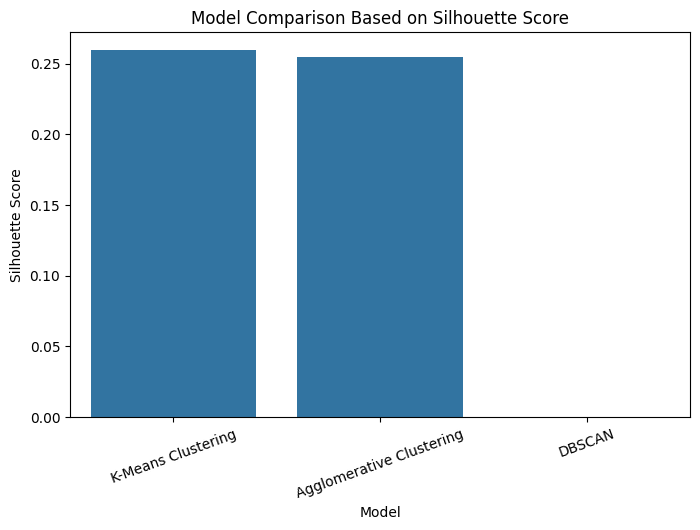

In [69]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Silhouette Score"
)

plt.title("Model Comparison Based on Silhouette Score")
plt.xlabel("Model")
plt.ylabel("Silhouette Score")
plt.xticks(rotation=20)
plt.show()

In [70]:

print("K-Means Cluster Counts:")
print(data_clean["KMeans_Cluster"].value_counts().sort_index())

print("\nAgglomerative Cluster Counts:")
print(data_clean["Agglomerative_Cluster"].value_counts().sort_index())

print("\nDBSCAN Cluster Counts:")
print(data_clean["DBSCAN_Cluster"].value_counts().sort_index())

K-Means Cluster Counts:
KMeans_Cluster
0     80
1    147
2    213
Name: count, dtype: int64

Agglomerative Cluster Counts:
Agglomerative_Cluster
0    262
1     53
2    125
Name: count, dtype: int64

DBSCAN Cluster Counts:
DBSCAN_Cluster
-1     96
 0    344
Name: count, dtype: int64


In [71]:

kmeans_cluster_profile

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Cluster,,,,,,
0,2898.575000,7135.937500,12569.712500,606.550000,5554.387500,782.862500
1,17042.836735,10559.666667,13333.598639,4133.095238,4987.020408,2846.591837
2,11938.723005,2005.685446,2502.093897,3265.544601,424.478873,891.384977


In [72]:


agg_cluster_profile

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Agglomerative_Cluster,,,,,,
0,15016.099237,3389.935115,3673.954198,4187.851145,616.805344,1552.751908
1,3913.962264,5222.981132,8657.924528,1198.415094,3474.113208,190.490566
2,9107.784000,11083.008000,16616.928000,1527.336000,7377.008000,2032.208000


In [73]:

dbscan_cluster_profile

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
DBSCAN_Cluster,,,,,,
-1,12315.822917,9030.322917,12007.479167,3628.468750,4301.083333,2184.770833
0,11912.244186,4893.738372,6819.313953,2916.619186,2485.328488,1340.712209


## 9. Final Model Selection and Customer Segmentation

**Selected model: K-Means with K = 3.** It has the highest silhouette score among the final models (≈ 0.259), assigns every customer to a segment, and produces segments that are easy to interpret.

In [74]:
# ==============================
# Final Selected Model
# ==============================

selected_model = "K-Means Clustering"
selected_number_of_clusters = 3

print("Selected Model:", selected_model)
print("Selected Number of Clusters:", selected_number_of_clusters)

Selected Model: K-Means Clustering
Selected Number of Clusters: 3


In [75]:


final_data = data_clean.copy()

final_data["Final_Cluster"] = final_data["KMeans_Cluster"]

final_data.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster,Agglomerative_Cluster,DBSCAN_Cluster,Final_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1,2,0,1
1,2,3,7057,9810,9568,1762,3293,1776,1,2,0,1
2,2,3,6353,8808,7684,2405,3516,7844,1,2,0,1
3,1,3,13265,1196,4221,6404,507,1788,2,0,0,2
4,2,3,22615,5410,7198,3915,1777,5185,1,0,0,1


In [76]:
final_cluster_profile = final_data.groupby("Final_Cluster")[spending_columns].mean()

final_cluster_profile

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Final_Cluster,,,,,,
0,2898.575000,7135.937500,12569.712500,606.550000,5554.387500,782.862500
1,17042.836735,10559.666667,13333.598639,4133.095238,4987.020408,2846.591837
2,11938.723005,2005.685446,2502.093897,3265.544601,424.478873,891.384977


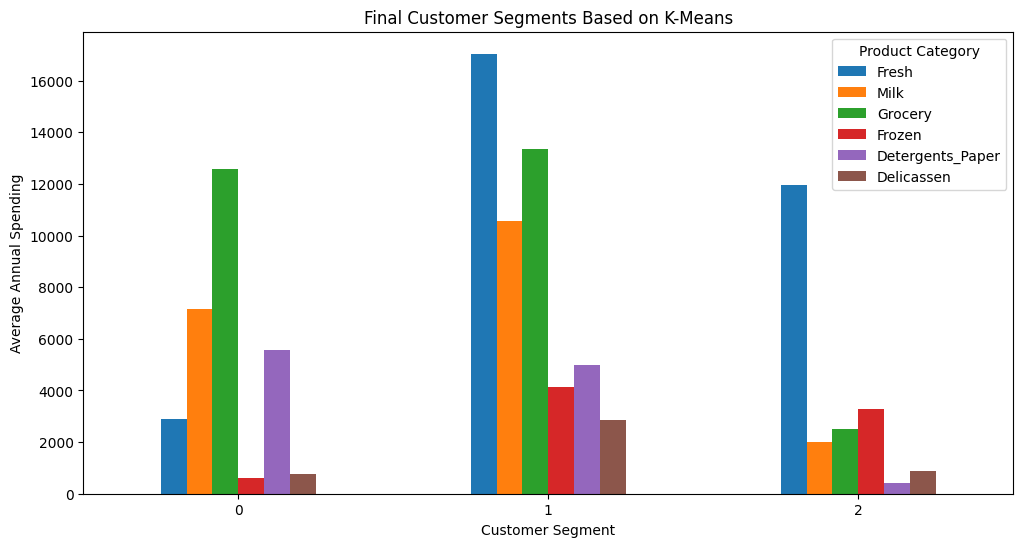

In [77]:
final_cluster_profile.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Final Customer Segments Based on K-Means")
plt.xlabel("Customer Segment")
plt.ylabel("Average Annual Spending")
plt.xticks(rotation=0)
plt.legend(title="Product Category")
plt.show()

In [78]:
final_cluster_counts = final_data["Final_Cluster"].value_counts().sort_index()

final_cluster_summary = final_cluster_profile.copy()
final_cluster_summary["Number of Customers"] = final_cluster_counts

final_cluster_summary

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Number of Customers
Final_Cluster,,,,,,,
0,2898.575000,7135.937500,12569.712500,606.550000,5554.387500,782.862500,80
1,17042.836735,10559.666667,13333.598639,4133.095238,4987.020408,2846.591837,147
2,11938.723005,2005.685446,2502.093897,3265.544601,424.478873,891.384977,213


In [79]:
final_data.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster,Agglomerative_Cluster,DBSCAN_Cluster,Final_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1,2,0,1
1,2,3,7057,9810,9568,1762,3293,1776,1,2,0,1
2,2,3,6353,8808,7684,2405,3516,7844,1,2,0,1
3,1,3,13265,1196,4221,6404,507,1788,2,0,0,2
4,2,3,22615,5410,7198,3915,1777,5185,1,0,0,1


In [80]:
segment_counts = final_data["Final_Cluster"].value_counts().sort_index()

segment_counts

,count
Final_Cluster,
0,80
1,147
2,213


In [81]:
segment_percentages = (
    final_data["Final_Cluster"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

segment_percentages

,proportion
Final_Cluster,
0,18.181818
1,33.409091
2,48.409091


In [82]:

segment_profile = final_data.groupby("Final_Cluster")[spending_columns].mean()

segment_profile

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Final_Cluster,,,,,,
0,2898.575000,7135.937500,12569.712500,606.550000,5554.387500,782.862500
1,17042.836735,10559.666667,13333.598639,4133.095238,4987.020408,2846.591837
2,11938.723005,2005.685446,2502.093897,3265.544601,424.478873,891.384977


In [83]:
segment_summary = segment_profile.copy()

segment_summary["Number of Customers"] = segment_counts
segment_summary["Percentage of Customers"] = segment_percentages.round(2)

segment_summary

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Number of Customers,Percentage of Customers
Final_Cluster,,,,,,,,
0,2898.575000,7135.937500,12569.712500,606.550000,5554.387500,782.862500,80,18.18
1,17042.836735,10559.666667,13333.598639,4133.095238,4987.020408,2846.591837,147,33.41
2,11938.723005,2005.685446,2502.093897,3265.544601,424.478873,891.384977,213,48.41


### 9.1 Segment spending index

The spending index divides each segment's average spending by the overall average. Values above 1 mean the segment spends more than average in that category.

In [84]:
overall_average_spending = final_data[spending_columns].mean()

segment_spending_index = segment_profile / overall_average_spending

segment_spending_index

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Final_Cluster,,,,,,
0,0.241542,1.231127,1.580842,0.197449,1.927607,0.513396
1,1.420201,1.821805,1.676913,1.345438,1.730707,1.866776
2,0.994869,0.346031,0.314678,1.063026,0.147312,0.584564


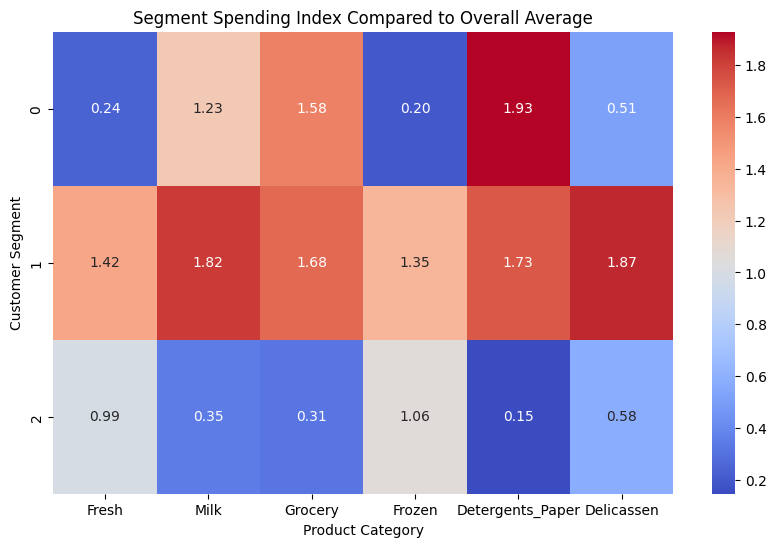

In [85]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    segment_spending_index,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Segment Spending Index Compared to Overall Average")
plt.xlabel("Product Category")
plt.ylabel("Customer Segment")
plt.show()

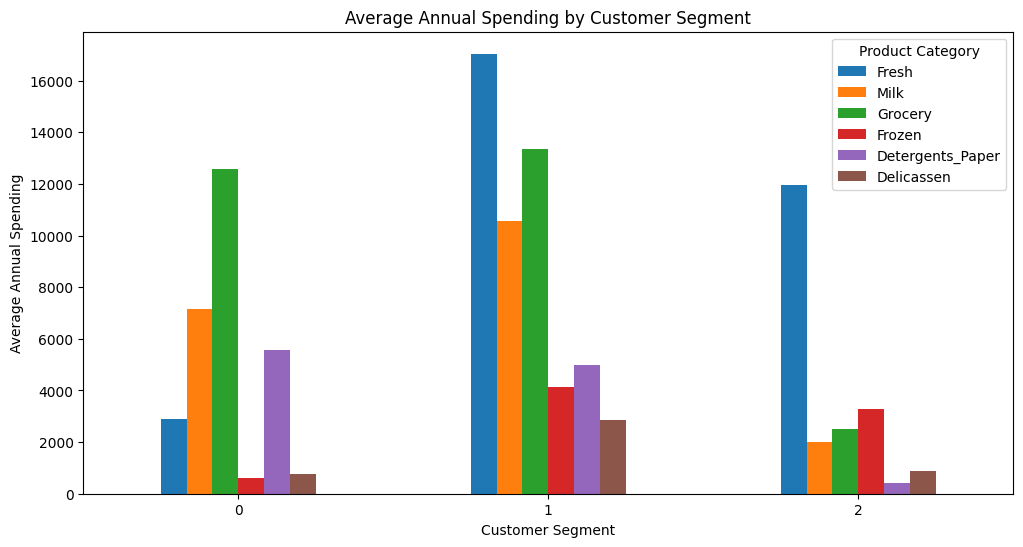

In [86]:

segment_profile.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Annual Spending by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Annual Spending")
plt.xticks(rotation=0)
plt.legend(title="Product Category")
plt.show()

In [87]:

top_category_per_segment = segment_profile.idxmax(axis=1)

top_category_per_segment

,0
Final_Cluster,
0,Grocery
1,Fresh
2,Fresh


In [88]:

segment_profile["Total_Average_Spending"] = segment_profile.sum(axis=1)

segment_profile.sort_values("Total_Average_Spending", ascending=False)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Total_Average_Spending
Final_Cluster,,,,,,,
1,17042.836735,10559.666667,13333.598639,4133.095238,4987.020408,2846.591837,52902.809524
0,2898.575000,7135.937500,12569.712500,606.550000,5554.387500,782.862500,29548.025000
2,11938.723005,2005.685446,2502.093897,3265.544601,424.478873,891.384977,21027.910798


### 9.2 Channel and region profile

`Channel` and `Region` were not used for clustering. Here they help describe each segment.

In [89]:
channel_distribution = pd.crosstab(
    final_data["Final_Cluster"],
    final_data["Channel"],
    normalize="index"
) * 100

channel_distribution.round(2)

Channel,1,2
Final_Cluster,,
0,40.00,60.00
1,38.10,61.90
2,98.59,1.41


In [90]:
region_distribution = pd.crosstab(
    final_data["Final_Cluster"],
    final_data["Region"],
    normalize="index"
) * 100

region_distribution.round(2)

Region,1,2,3
Final_Cluster,,,
0,17.50,12.50,70.00
1,15.65,7.48,76.87
2,18.78,12.21,69.01


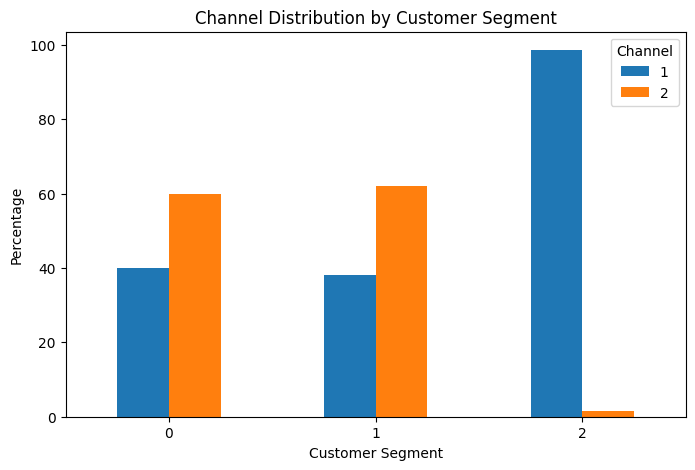

In [91]:

channel_distribution.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Channel Distribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Channel")
plt.show()

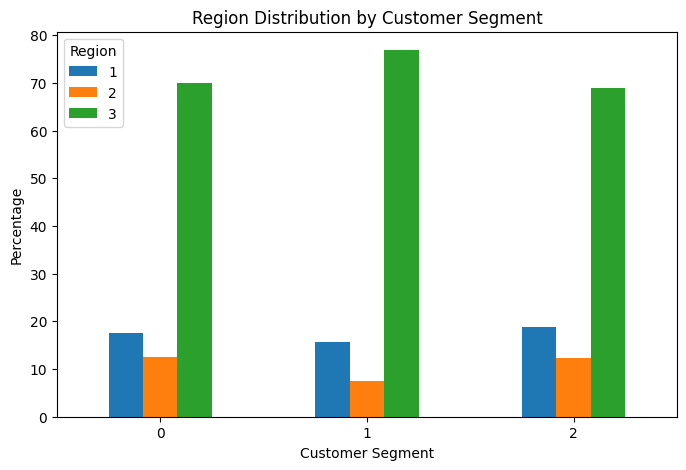

In [92]:
region_distribution.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Region Distribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Region")
plt.show()

### 9.3 Segment labels

The code below generates labels automatically from each segment's highest absolute spending category. Segments 1 and 2 both get "High Fresh", so the final report and README use these descriptive names instead:

| Segment | Descriptive name | Customers |
|---|---|---|
| 0 | Retail grocery-focused customers | 80 |
| 1 | High-value broad spenders | 147 |
| 2 | Fresh-focused traditional customers | 213 |

In [93]:
segment_names = {}

for cluster in segment_summary.index:
    top_category = segment_summary.loc[cluster, spending_columns].idxmax()
    customer_count = segment_summary.loc[cluster, "Number of Customers"]

    segment_names[cluster] = f"Segment {cluster}: High {top_category} Customers"

segment_names

{0: 'Segment 0: High Grocery Customers',
 1: 'Segment 1: High Fresh Customers',
 2: 'Segment 2: High Fresh Customers'}

In [94]:

final_data["Segment_Name"] = final_data["Final_Cluster"].map(segment_names)

final_data[["Final_Cluster", "Segment_Name"]].head()

,Final_Cluster,Segment_Name
0,1,Segment 1: High Fresh Customers
1,1,Segment 1: High Fresh Customers
2,1,Segment 1: High Fresh Customers
3,2,Segment 2: High Fresh Customers
4,1,Segment 1: High Fresh Customers


In [95]:
final_segment_report = segment_summary.copy()

final_segment_report["Top Spending Category"] = top_category_per_segment
final_segment_report["Segment Name"] = final_segment_report.index.map(segment_names)

final_segment_report

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Number of Customers,Percentage of Customers,Top Spending Category,Segment Name
Final_Cluster,,,,,,,,,,
0,2898.575000,7135.937500,12569.712500,606.550000,5554.387500,782.862500,80,18.18,Grocery,Segment 0: High Grocery Customers
1,17042.836735,10559.666667,13333.598639,4133.095238,4987.020408,2846.591837,147,33.41,Fresh,Segment 1: High Fresh Customers
2,11938.723005,2005.685446,2502.093897,3265.544601,424.478873,891.384977,213,48.41,Fresh,Segment 2: High Fresh Customers


## 10. Business Insights

| Segment | Profile | Recommended actions |
|---|---|---|
| **0: Retail grocery-focused** (80, 18.18%) | High Grocery, Milk, and Detergents_Paper; low Fresh and Frozen; 60% Retail channel | Grocery and detergents/paper bundles, frequent-purchase promotions, stock packaged and replenishable goods |
| **1: High-value broad spenders** (147, 33.41%) | Above-average spending in every category; highest total spending | Priority account management, cross-selling, broad product availability |
| **2: Fresh-focused traditional** (213, 48.41%) | Fresh and Frozen near average; low Grocery, Milk, and Detergents_Paper; ~99% Horeca channel | Reliable fresh supply, bulk fresh offers, upselling into Frozen and Delicassen |

## 11. Conclusion

- Preprocessing (log transformation + standard scaling) was needed because the spending features are highly skewed and on different scales.
- **K-Means (K = 3)** was selected over Agglomerative Clustering (silhouette ≈ 0.255) and DBSCAN (one cluster plus 96 noise points).
- K = 3 was chosen for interpretability, even though K = 2 had a higher silhouette score.
- The silhouette score of ≈ 0.259 indicates moderate, overlapping cluster structure. The segments should be validated with business stakeholders before use.

**Limitations and next steps:** the data contains only annual spending, channel, and region. Adding profitability, purchase frequency, and transaction history, and running cluster stability analysis, would make the segmentation more reliable.